# Import libraries

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Descriptors
import numpy as np

# Load actual and generated smiles

In [11]:
file1 = "matches_above_0.8.csv"
file2 = "ESOL_dataset.csv"  # Replace with your second file

df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)

# The SMILES column in both files
smiles1 = df1["smiles"].dropna().astype(str)
smiles2 = df2["SMILES"].dropna().astype(str)





# Calculate RDKit features

In [12]:
def calculate_features(smiles_list, dataset_name):
    results = []
    invalid_smiles = []

    for smiles in smiles_list:
        mol = Chem.MolFromSmiles(smiles)

        if mol is None:
            invalid_smiles.append(smiles)
            continue

        results.append({
            "SMILES": smiles,
            "LogP": Descriptors.MolLogP(mol),
            "TPSA": Descriptors.TPSA(mol),
            "MolWt": Descriptors.MolWt(mol),
            "Dataset": dataset_name
        })

    print(
        f"{dataset_name}: {len(results)} valid, "
        f"{len(invalid_smiles)} invalid SMILES"
    )

    return pd.DataFrame(results)

features1 = calculate_features(smiles1, "Dataset 1")
features2 = calculate_features(smiles2, "Dataset 2")

# Combine both datasets
features = pd.concat(
    [features1, features2],
    ignore_index=True
)

# Save all calculated features
features.to_csv("compared_molecular_features.csv", index=False)


Dataset 1: 88 valid, 0 invalid SMILES
Dataset 2: 1128 valid, 0 invalid SMILES


#  LogP vs TPSA

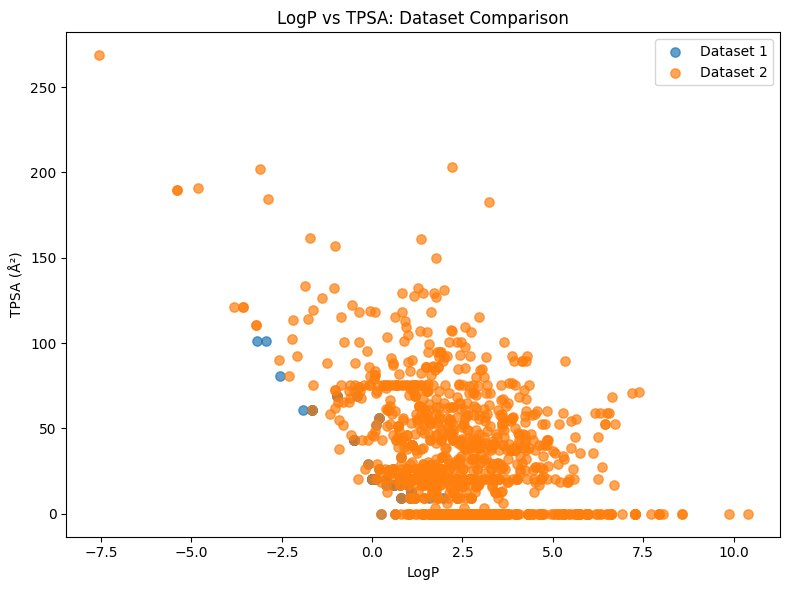

In [13]:
plt.figure(figsize=(8, 6))

for name, group in features.groupby("Dataset"):
    plt.scatter(
        group["LogP"],
        group["TPSA"],
        alpha=0.7,
        s=45,
        label=name
    )

plt.xlabel("LogP")
plt.ylabel("TPSA (Å²)")
plt.title("LogP vs TPSA: Dataset Comparison")
plt.legend()
plt.tight_layout()
plt.savefig("comparison_logP_TPSA.png", dpi=300)
plt.show()

# Molecular weight distribution

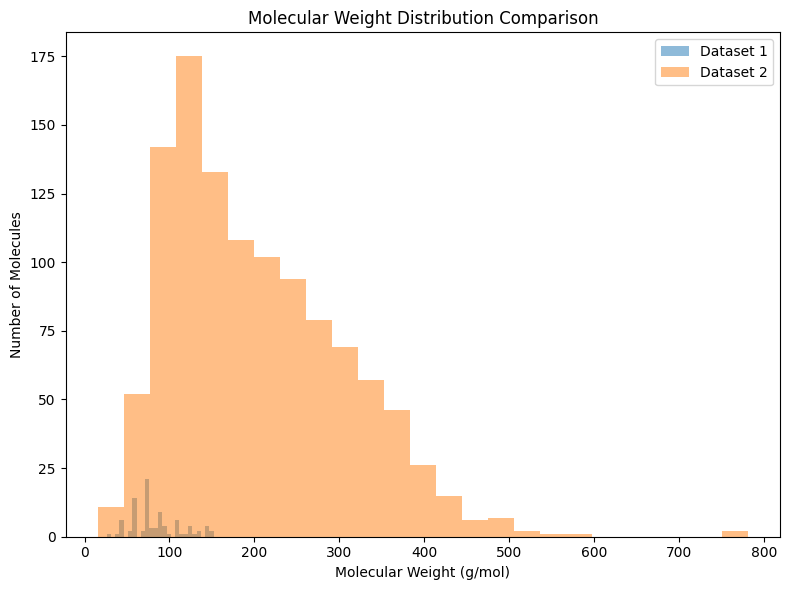

In [14]:
plt.figure(figsize=(8, 6))

for name, group in features.groupby("Dataset"):
    plt.hist(
        group["MolWt"],
        bins=25,
        alpha=0.5,
        label=name
    )

plt.xlabel("Molecular Weight (g/mol)")
plt.ylabel("Number of Molecules")
plt.title("Molecular Weight Distribution Comparison")
plt.legend()
plt.tight_layout()
plt.savefig("comparison_molecular_weight.png", dpi=300)
plt.show()


# Compare summary statistics

In [15]:
summary = features.groupby("Dataset")[
    ["LogP", "TPSA", "MolWt"]
].agg(["mean", "median", "std"])

print("\nSummary statistics:")
print(summary)


Summary statistics:
               LogP                         TPSA                    \
               mean  median       std       mean median        std   
Dataset                                                              
Dataset 1  0.469104  0.7772  1.087562  27.694091  20.23  20.867284   
Dataset 2  2.447520  2.3390  1.852875  34.872881  26.30  35.383593   

                MolWt                       
                 mean   median         std  
Dataset                                     
Dataset 1   83.750261   74.123   28.193988  
Dataset 2  203.937074  182.179  102.738077  
